In [47]:
import pandas as pd
import numpy as np
import string
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import joblib


In [48]:
file_path = '/content/dataset-qadeer.csv'
df = pd.read_csv(file_path, encoding='latin1')
df.head()


,text,label
0,Legends watching,non-abusive
1,watching after 4 years,non-abusive
2,legend watching in 2025,non-abusive
3,mza aaya lekin jo roasting carryminati krta ha...,non-abusive
4,zanda baidahain ducky,non-abusive


In [49]:
df.columns

Index(['text', 'label'], dtype='object')

In [50]:
unique_labels = df['label'].unique()
print("Unique values in the 'label' column:")

unique_labels


Unique values in the 'label' column:


array(['non-abusive', 'abusive'], dtype=object)

In [51]:
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values)


Missing values in each column:
text     0
label    0
dtype: int64


In [52]:
df = df.dropna(subset=['text', 'label']).reset_index(drop=True)

# Confirm missing values are handled
print("Missing values after handling:")
print(df.isnull().sum())


Missing values after handling:
text     0
label    0
dtype: int64


In [53]:
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")


Number of duplicate rows: 2300


In [54]:
df = df.drop_duplicates().reset_index(drop=True)

# Confirm duplicates removed
print(f"Dataset shape after removing duplicates: {df.shape}")


Dataset shape after removing duplicates: (19822, 2)


In [55]:
df['text_length'] = df['text'].apply(len)
print("Text length statistics:")
print(df['text_length'].describe())

# Optional: Remove extremely short or long comments as noise
df = df[(df['text_length'] > 5) & (df['text_length'] < 500)].reset_index(drop=True)


Text length statistics:
count    19822.000000
mean        53.431541
std         56.517705
min          2.000000
25%         23.000000
50%         38.000000
75%         65.000000
max       2412.000000
Name: text_length, dtype: float64


In [56]:
df.shape

(19745, 3)

In [57]:
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

df['text'] = df['text'].apply(normalize_text)
df.head()


,text,label,text_length
0,legends watching,non-abusive,16
1,watching after 4 years,non-abusive,22
2,legend watching in 2025,non-abusive,23
3,mza aaya lekin jo roasting carryminati krta ha...,non-abusive,71
4,zanda baidahain ducky,non-abusive,22


In [58]:
roman_urdu_stopwords = [
    'aur','ka','ki','se','ke','hai','ho','mein','kya','main','kaise','hoon','tum','aap','sab',
    'bhi','hain','na','naheen','to','par','kiya','wahan','yahan','ab','jo','pe','phir','kyunki',
    'mujhe','tumhe','ap','is','wo','chal','theek','hua','tumhare','meray','kam','agar','kaam',
    'kar','yad','kuch','jaldi','iss','yahi','kisi','nahi','apne','aaj','kal','wahi','waise'
]

def remove_stopwords(text):
    words = text.split()
    filtered_words = [word for word in words if word not in roman_urdu_stopwords]
    return ' '.join(filtered_words)

df['text'] = df['text'].apply(remove_stopwords)
df.head()


,text,label,text_length
0,legends watching,non-abusive,16
1,watching after 4 years,non-abusive,22
2,legend watching in 2025,non-abusive,23
3,mza aaya lekin roasting carryminati krta hi mza,non-abusive,71
4,zanda baidahain ducky,non-abusive,22


In [59]:
# Convert labels to "A" for abusive and "NA" for non-abusive
df['label'] = df['label'].replace({'non-abusive': 'NA', 'abusive': 'A'})

# Display counts and first few rows
print(df['label'].value_counts())
df.head()


label
NA    18041
A      1704
Name: count, dtype: int64


,text,label,text_length
0,legends watching,NA,16
1,watching after 4 years,NA,22
2,legend watching in 2025,NA,23
3,mza aaya lekin roasting carryminati krta hi mza,NA,71
4,zanda baidahain ducky,NA,22


In [60]:
# Use only the first 5000 rows of the dataset
df_subset = df.head(5000).copy()

# Count how many should be Non-Abusive (70%) and Abusive (30%)
num_rows = len(df_subset)
num_na = int(0.7 * num_rows)  # 70% Non-Abusive
num_a = num_rows - num_na     # 30% Abusive

# Separate NA and A categories from the subset
na_data = df_subset[df_subset['label'] == 'NA'].sample(n=num_na, replace=True, random_state=42)
a_data = df_subset[df_subset['label'] == 'A'].sample(n=num_a, replace=True, random_state=42)

# Concatenate and shuffle
balanced_data = pd.concat([na_data, a_data]).sample(frac=1, random_state=42).reset_index(drop=True)

# Display size and first few rows
print("Balanced dataset shape:", balanced_data.shape)
balanced_data.head()


Balanced dataset shape: (5000, 3)


,text,label,text_length
0,yarrrrrrrrrrrrrrrrrrrrrrr kayy video bani yhaa...,NA,111
1,alex bhati ko dislike di a ha ok,NA,36
2,asi hi in marty rahobrmaza a raha,NA,42
3,coutha,NA,6
4,dacky bhai love you,NA,19


In [61]:
# Initialize TF-IDF vectorizer with ngram_range (1,3) to include Uni, Bi, and Tri-Grams
vectorizer_ngram = TfidfVectorizer(ngram_range=(1,3))

# Fit and transform the text data
X_ngram = vectorizer_ngram.fit_transform(balanced_data['text'])
y = balanced_data['label']

# Display the feature matrix shape
print(f"Combined N-Gram (Uni+Bi+Tri) Feature Shape: {X_ngram.shape}")



Combined N-Gram (Uni+Bi+Tri) Feature Shape: (5000, 38528)


In [62]:
# Split the dataset into 75% training and 25% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_ngram,
    y,
    test_size=0.25,   # 25% test data
    random_state=42,  # For reproducibility
    stratify=y        # Maintain class distribution in train and test sets
)

# Display the shapes of the splits
print(f"Training Data Shape: {X_train.shape}, Training Labels Shape: {y_train.shape}")
print(f"Testing Data Shape: {X_test.shape}, Testing Labels Shape: {y_test.shape}")


Training Data Shape: (3750, 38528), Training Labels Shape: (3750,)
Testing Data Shape: (1250, 38528), Testing Labels Shape: (1250,)


In [63]:
# Initialize models
nb_model = MultinomialNB()
svm_model = SVC(kernel='rbf')
dt_model = DecisionTreeClassifier(random_state=42)

# Train
nb_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)

# Predict
nb_pred = nb_model.predict(X_test)
svm_pred = svm_model.predict(X_test)
dt_pred = dt_model.predict(X_test)


---Naive Bayes---
Accuracy: 0.9408
Precision: 1.0
Recall: 0.8026666666666666
F1 Score: 0.8905325443786982
              precision    recall  f1-score   support

          NA       1.00      0.80      0.89       375
           A       0.92      1.00      0.96       875

    accuracy                           0.94      1250
   macro avg       0.96      0.90      0.92      1250
weighted avg       0.95      0.94      0.94      1250



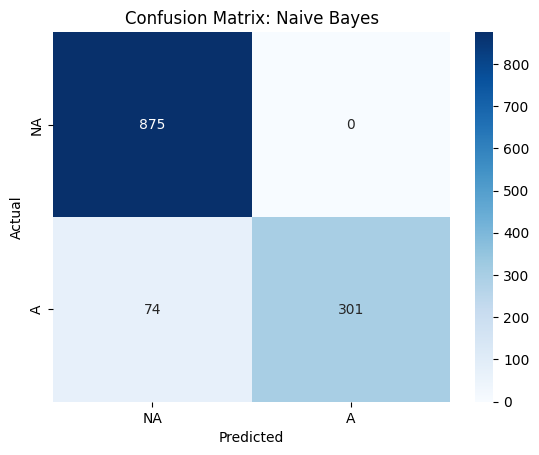

---SVM---
Accuracy: 0.9696
Precision: 1.0
Recall: 0.8986666666666666
F1 Score: 0.9466292134831461
              precision    recall  f1-score   support

          NA       1.00      0.90      0.95       375
           A       0.96      1.00      0.98       875

    accuracy                           0.97      1250
   macro avg       0.98      0.95      0.96      1250
weighted avg       0.97      0.97      0.97      1250



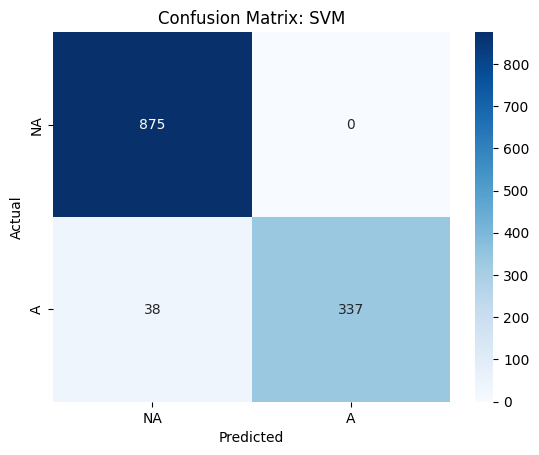

---Decision Tree---
Accuracy: 0.9752
Precision: 0.955026455026455
Recall: 0.9626666666666667
F1 Score: 0.9588313413014609
              precision    recall  f1-score   support

          NA       0.96      0.96      0.96       375
           A       0.98      0.98      0.98       875

    accuracy                           0.98      1250
   macro avg       0.97      0.97      0.97      1250
weighted avg       0.98      0.98      0.98      1250



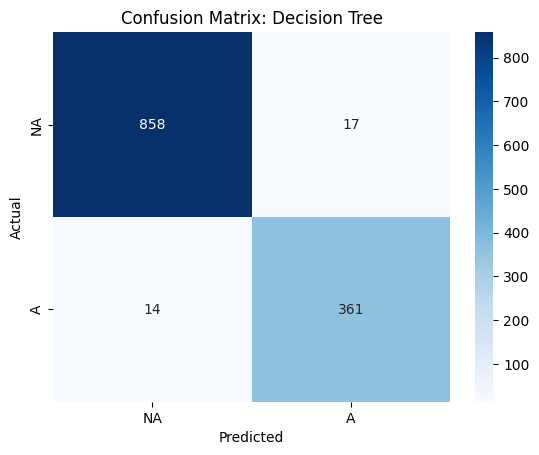

In [65]:
models = {'Naive Bayes': nb_pred, 'SVM': svm_pred, 'Decision Tree': dt_pred}

for name, pred in models.items():
    print(f"---{name}---")
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, pos_label='A'))
    print("Recall:", recall_score(y_test, pred, pos_label='A'))
    print("F1 Score:", f1_score(y_test, pred, pos_label='A'))
    print(classification_report(y_test, pred, target_names=['NA','A']))

    cm = confusion_matrix(y_test, pred, labels=['NA','A'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['NA','A'], yticklabels=['NA','A'])
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


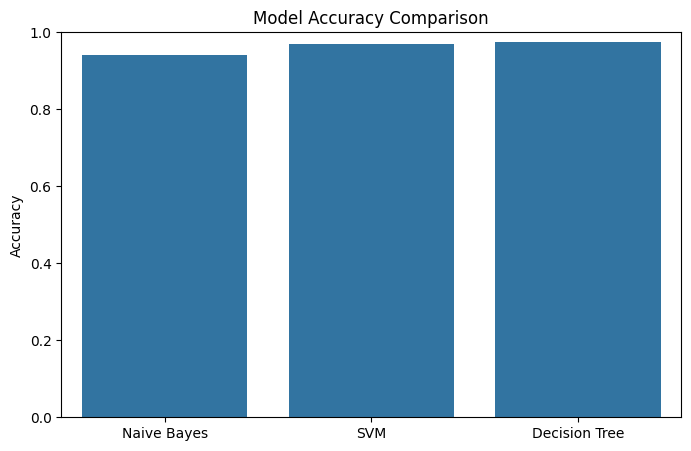

In [66]:
accuracy_scores = {
    'Naive Bayes': accuracy_score(y_test, nb_pred),
    'SVM': accuracy_score(y_test, svm_pred),
    'Decision Tree': accuracy_score(y_test, dt_pred)
}

plt.figure(figsize=(8,5))
sns.barplot(x=list(accuracy_scores.keys()), y=list(accuracy_scores.values()))
plt.ylim(0,1)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.show()


In [67]:
# Save trained models
joblib.dump(nb_model, 'naive_bayes_model.pkl')
joblib.dump(svm_model, 'svm_model.pkl')
joblib.dump(dt_model, 'decision_tree_model.pkl')

# Save the single N-Gram TF-IDF vectorizer
joblib.dump(vectorizer_ngram, 'vectorizer_ngram.pkl')



['vectorizer_ngram.pkl']